**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
!pip install prophet

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

from prophet import Prophet

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')


In [3]:
!pip install kagglehub

import kagglehub
import pandas as pd

path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

print("Шлях до файлу датасету:", path)

import os
files = os.listdir(path)
print("Файли в папці:", files)

csv_file_name = [f for f in files if f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file_name))

print("\n--- Перші рядки датасету ---")
print(df.head())


Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.
Шлях до файлу датасету: /kaggle/input/daily-climate-time-series-data-delhi-india
Файли в папці: ['kaggel_weather_2013_to_2024.csv']

--- Перші рядки датасету ---
   Unnamed: 0       DATE  tempmax  tempmin  temp  feelslikemax  feelslikemin  \
0           0  4/14/2013     37.7     23.1  28.7          35.4          23.1   
1           1  4/15/2013     37.5     21.1  28.6          35.3          21.1   
2           2  4/16/2013     40.1     21.9  31.7          37.5          21.9   
3           3  4/17/2013     36.4     21.0  29.9          34.0          21.0   
4           4  4/18/2013     37.5     21.7  30.6          35.2          21.7   

   feelslike  humidity  precip  ...  year-2000  weekofyear  tempmax_humidity  \
0       28.1      39.7     2.0  ...         13          15           1496.69   
1       28.0      41.7     0.0  ...         13          16           1563.75   
2       30.4      30

In [4]:
# Перевірка зчитаного DataFrame
print("Розмір датасету:", df.shape)
print("\nНазви перших 5 стовпчиків:")
print(df.columns[:5])

# Виведення перших рядків
display(df.head())


Розмір датасету: (3557, 29)

Назви перших 5 стовпчиків:
Index(['Unnamed: 0', 'DATE', 'tempmax', 'tempmin', 'temp'], dtype='object')


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


Підготовка даних

In [7]:
date_col = 'DATE' if 'DATE' in df.columns else ('date' if 'date' in df.columns else df.columns[0])

if df.index.name != date_col:
    df[date_col] = pd.to_datetime(df[date_col])
    df = df.sort_values(date_col)
    df.set_index(date_col, inplace=True)

print("Готово! Індекс успішно встановлено.")

Готово! Індекс успішно встановлено.


In [8]:
# Перегляньте інформацію про структуру датасету
print("--- Інформація про структуру (info) ---")
df.info()

print("\Перші 5 рядків датасету (head):")
display(df.head())


--- Інформація про структуру (info) ---
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 1970-01-01 00:00:00 to 1970-01-01 00:00:00.000003556
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3557 non-null   float64
 1   tempmin                3557 non-null   float64
 2   temp                   3557 non-null   float64
 3   feelslikemax           3557 non-null   float64
 4   feelslikemin           3557 non-null   float64
 5   feelslike              3557 non-null   float64
 6   humidity               3557 non-null   float64
 7   precip                 3557 non-null   float64
 8   precipprob             3557 non-null   int64  
 9   precipcover            3557 non-null   float64
 10  windspeed              3557 non-null   float64
 11  sealevelpressure       3557 non-null   float64
 12  conditions             3557 non-null   object 
 13  Year                  

,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,precipcover,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
Unnamed: 0,,,,,,,,,,,,,,,,,,,,,
1970-01-01 00:00:00.000000000,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,100,4.17,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1970-01-01 00:00:00.000000001,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,0,0.00,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
1970-01-01 00:00:00.000000002,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,0,0.00,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
1970-01-01 00:00:00.000000003,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,0,0.00,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
1970-01-01 00:00:00.000000004,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,0,0.00,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [10]:
missing_data = df.isnull().sum()
print("Кількість пропущених значень у стовпчиках:")
print(missing_data[missing_data > 0])

df = df.interpolate(method='time')
print("\nПропущені значення оброблено.")

Кількість пропущених значень у стовпчиках:
Series([], dtype: int64)

Пропущені значення оброблено.


/tmp/ipykernel_472/406977026.py:5: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df = df.interpolate(method='time')


Графік температури

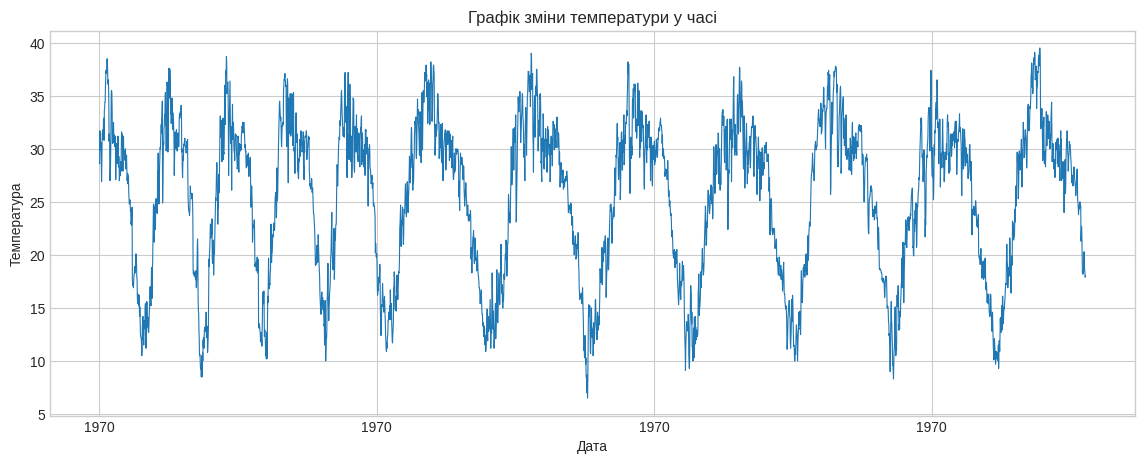

In [11]:
temp_col = 'temp' if 'temp' in df.columns else [c for c in df.columns if 'temp' in c.lower()][0]

plt.figure(figsize=(14, 5))
plt.plot(df.index, df[temp_col], color='tab:blue', linewidth=0.8)
plt.title('Графік зміни температури у часі')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.grid(True)
plt.show()


Ковзне середнє

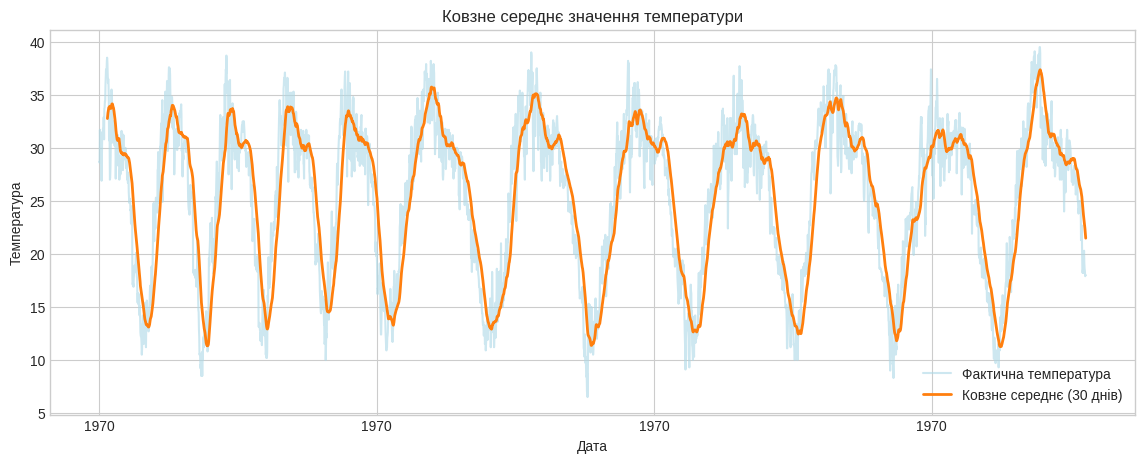

In [12]:
window_size = 30
df['rolling_mean'] = df[temp_col].rolling(window=window_size).mean()

plt.figure(figsize=(14, 5))
plt.plot(df.index, df[temp_col], label='Фактична температура', color='lightblue', alpha=0.6)
plt.plot(df.index, df['rolling_mean'], label=f'Ковзне середнє ({window_size} днів)', color='tab:orange', linewidth=2)
plt.title('Ковзне середнє значення температури')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()


Розподіл температури

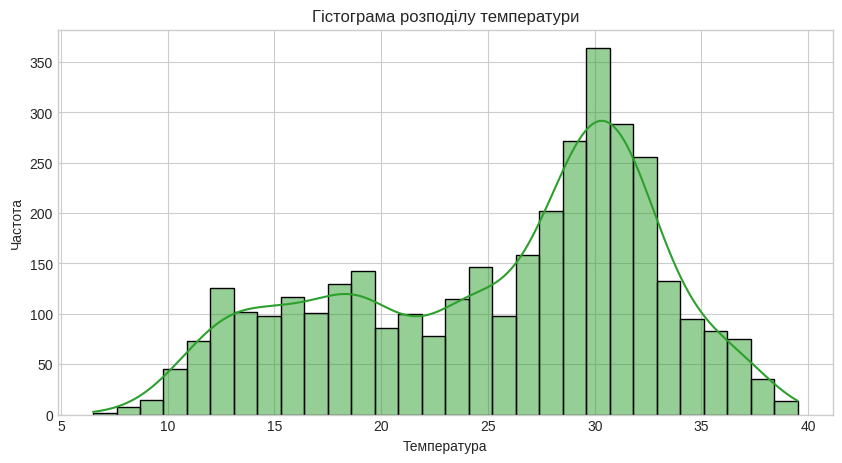

In [13]:
temp_col = 'temp' if 'temp' in df.columns else [c for c in df.columns if 'temp' in c.lower()][0]

plt.figure(figsize=(10, 5))
sns.histplot(df[temp_col].dropna(), kde=True, color='tab:green', bins=30)
plt.title('Гістограма розподілу температури')
plt.xlabel('Температура')
plt.ylabel('Частота')
plt.grid(True)
plt.show()


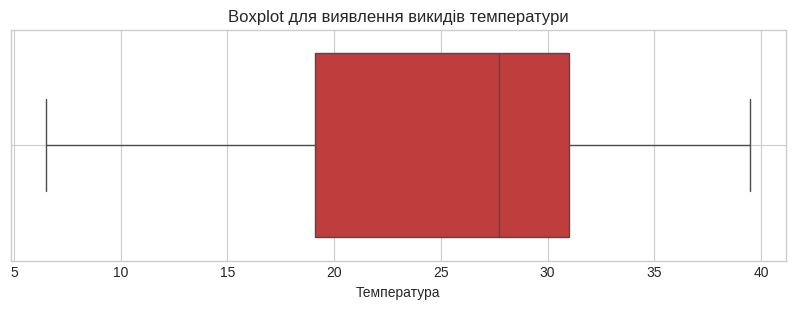

In [14]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=df[temp_col].dropna(), color='tab:red')
plt.title('Boxplot для виявлення викидів температури')
plt.xlabel('Температура')
plt.grid(True)
plt.show()


Аналіз автокореляції
ACF

PACF

<Figure size 1200x500 with 0 Axes>

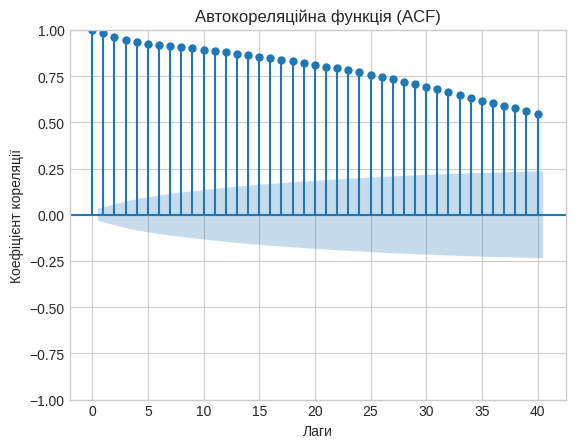

In [15]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(12, 5))
plot_acf(df[temp_col].dropna(), lags=40, alpha=0.05)
plt.title('Автокореляційна функція (ACF)')
plt.xlabel('Лаги')
plt.ylabel('Коефіцієнт кореляції')
plt.grid(True)
plt.show()


Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

<Figure size 1200x500 with 0 Axes>

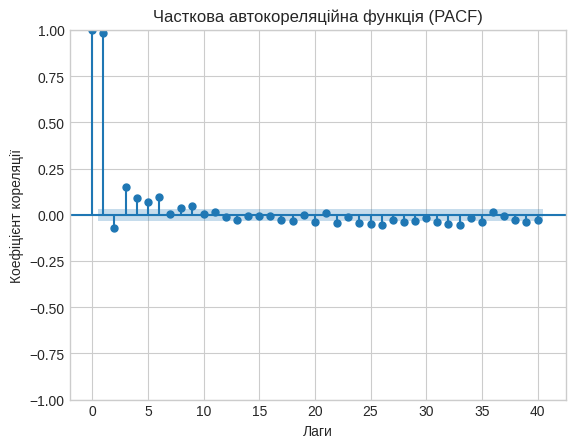

In [16]:
from statsmodels.graphics.tsaplots import plot_pacf

plt.figure(figsize=(12, 5))
plot_pacf(df[temp_col].dropna(), lags=40, alpha=0.05, method='ywm')
plt.title('Часткова автокореляційна функція (PACF)')
plt.xlabel('Лаги')
plt.ylabel('Коефіцієнт кореляції')
plt.grid(True)
plt.show()


Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [17]:
temp_col = 'temp' if 'temp' in df.columns else [c for c in df.columns if 'temp' in c.lower()][0]
ts_data = df[temp_col].dropna()

train_size = int(len(ts_data) * 0.8)
train_data = ts_data.iloc[:train_size]
test_data = ts_data.iloc[train_size:]

print(f"Розмір тренувальної вибірки: {len(train_data)}")
print(f"Розмір тестової вибірки: {len(test_data)}")


Розмір тренувальної вибірки: 2845
Розмір тестової вибірки: 712


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [18]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(train_data, order=(5, 1, 0))
arima_fit = arima_model.fit()

arima_pred = arima_fit.forecast(steps=len(test_data))
arima_pred.index = test_data.index


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ns will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ns will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency ns will be used.
  self._init_dates(dates, freq)


In [19]:
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 2845
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -4972.311
Date:                Thu, 22 Oct 2026   AIC                           9956.622
Time:                        17:18:05   BIC                           9992.339
Sample:                    01-01-1970   HQIC                          9969.504
                         - 01-01-1970                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0458      0.016      2.895      0.004       0.015       0.077
ar.L2         -0.1792      0.017    -10.551      0.000      -0.212      -0.146
ar.L3         -0.1160      0.017     -6.849      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

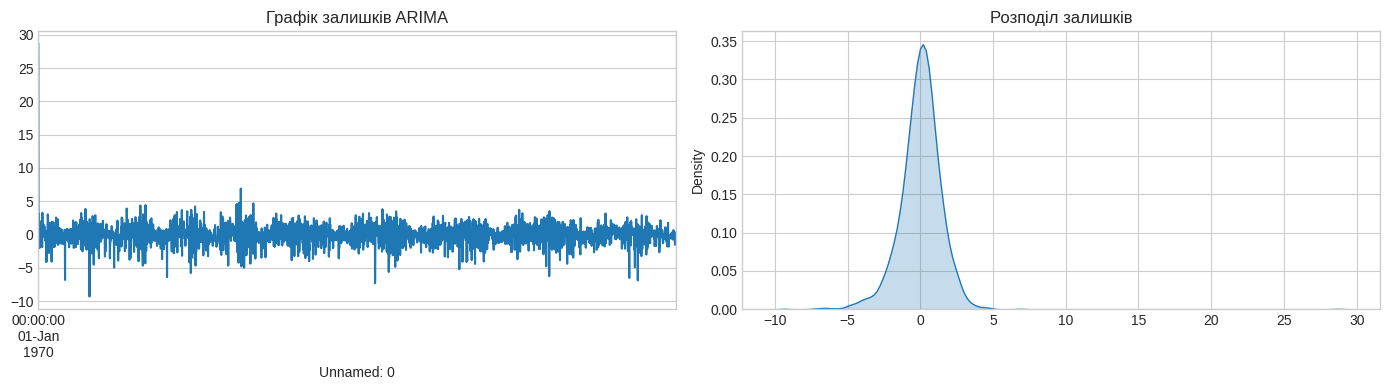

In [21]:
residuals = pd.Series(arima_fit.resid)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

residuals.plot(ax=axes[0])
axes[0].set_title('Графік залишків ARIMA')

sns.kdeplot(residuals, ax=axes[1], fill=True)
axes[1].set_title('Розподіл залишків')

plt.tight_layout()
plt.show()

In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import numpy as np

# Обчислення метрик
mae = mean_absolute_error(test_data, arima_pred)
rmse = np.sqrt(mean_squared_error(test_data, arima_pred))
mape = mean_absolute_percentage_error(test_data, arima_pred) * 100

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")


MAE:  11.0963
RMSE: 12.6831
MAPE: 40.12%


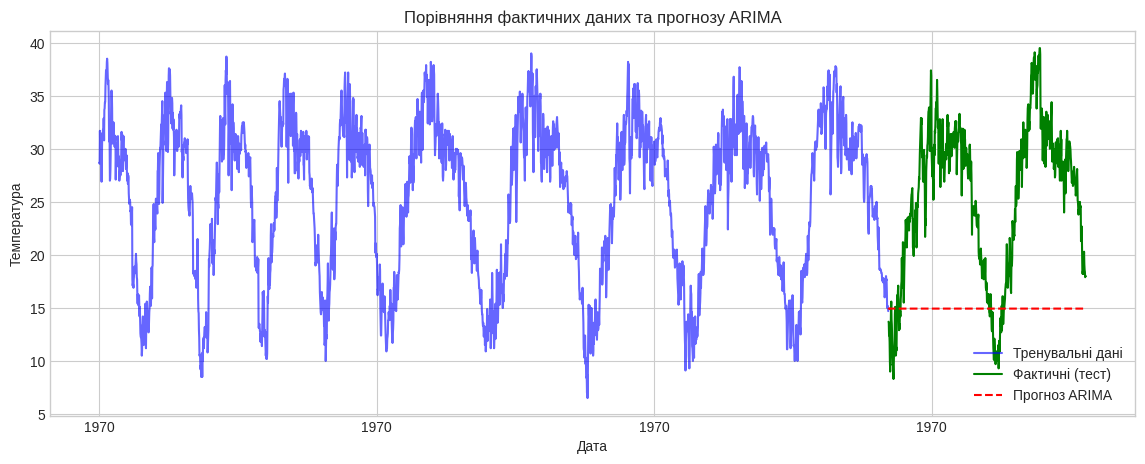

In [23]:
# Візуалізація фактичних значень та прогнозу ARIMA
plt.figure(figsize=(14, 5))
plt.plot(train_data.index, train_data, label='Тренувальні дані', color='blue', alpha=0.6)
plt.plot(test_data.index, test_data, label='Фактичні (тест)', color='green')
plt.plot(test_data.index, arima_pred, label='Прогноз ARIMA', color='red', linestyle='--')
plt.title('Порівняння фактичних даних та прогнозу ARIMA')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()


PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [24]:
df_prophet = train_data.reset_index()
date_col = df_prophet.columns[0]
temp_col = df_prophet.columns[1]

df_prophet = df_prophet.rename(columns={date_col: 'ds', temp_col: 'y'})


In [25]:
from prophet import Prophet

prophet_model = Prophet(daily_seasonality=True, yearly_seasonality=True)
prophet_model.fit(df_prophet)


INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.


Прогноз

In [26]:
future = prophet_model.make_future_dataframe(periods=len(test_data), freq='D')
forecast = prophet_model.predict(future)

prophet_pred = forecast.iloc[-len(test_data):]['yhat'].values
prophet_pred = pd.Series(prophet_pred, index=test_data.index)


In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import numpy as np

mae_p = mean_absolute_error(test_data, prophet_pred)
rmse_p = np.sqrt(mean_squared_error(test_data, prophet_pred))
mape_p = mean_absolute_percentage_error(test_data, prophet_pred) * 100

print(f"MAE (Prophet):  {mae_p:.4f}")
print(f"RMSE (Prophet): {rmse_p:.4f}")
print(f"MAPE (Prophet): {mape_p:.2f}%")


MAE (Prophet):  33345818853584.6367
RMSE (Prophet): 38490931761408.6641
MAPE (Prophet): 138106781273884.67%


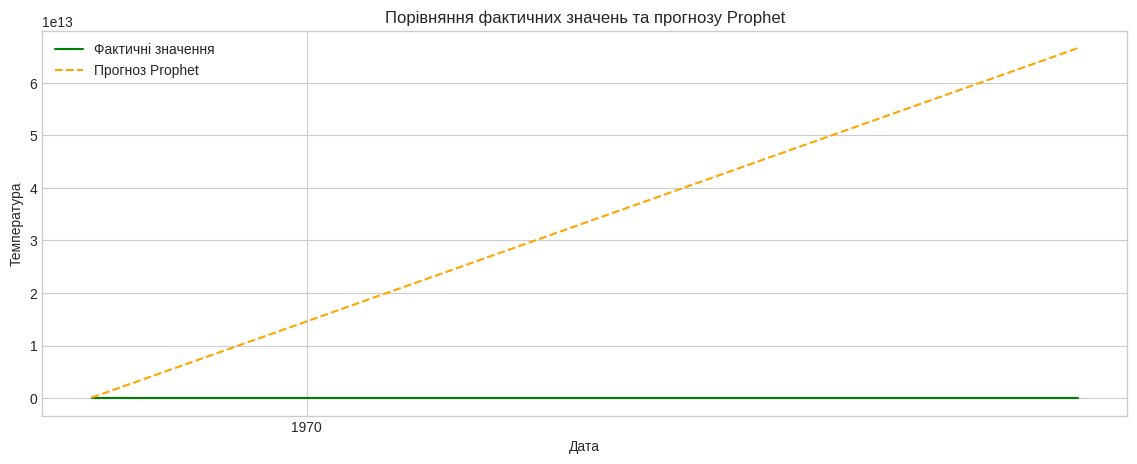

In [28]:
# Візуалізація прогнозів Prophet
plt.figure(figsize=(14, 5))
plt.plot(test_data.index, test_data, label='Фактичні значення', color='green')
plt.plot(test_data.index, prophet_pred, label='Прогноз Prophet', color='orange', linestyle='--')
plt.title('Порівняння фактичних значень та прогнозу Prophet')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()

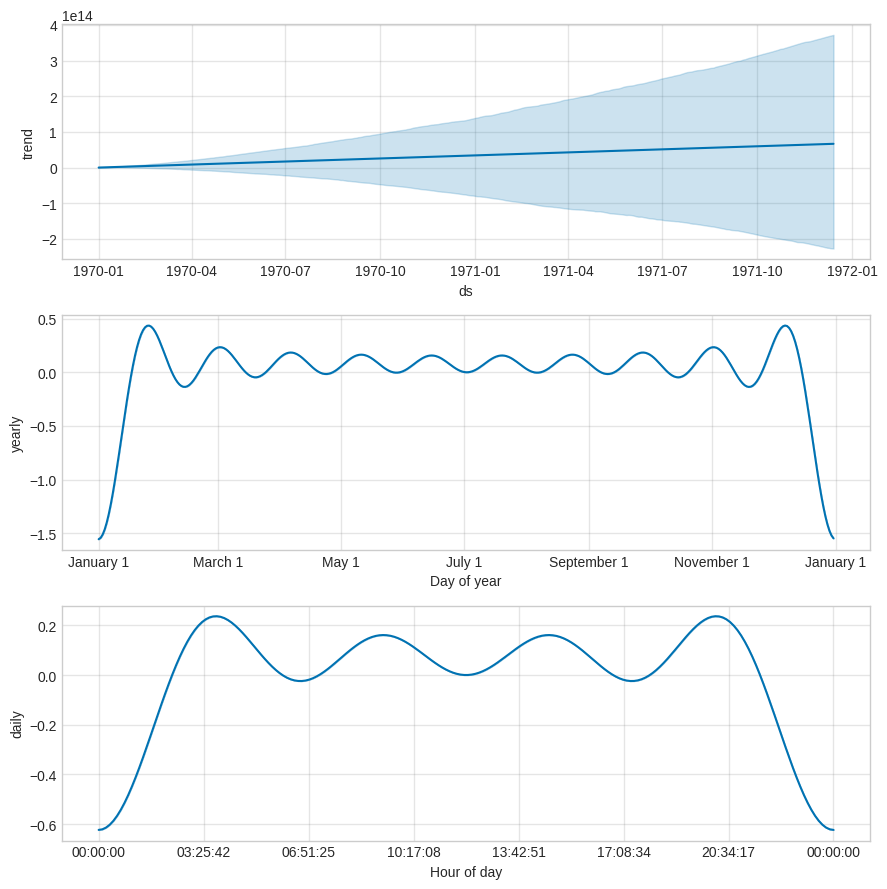

In [29]:
fig1 = prophet_model.plot_components(forecast)
plt.show()


ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [30]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(ts_data.values.reshape(-1, 1))

def create_sequences(dataset, look_back=30):
    X, y = [], []
    for i in range(len(dataset) - look_back):
        X.append(dataset[i:(i + look_back), 0])
        y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(y)

look_back = 30
X, y = create_sequences(scaled_data, look_back)


In [31]:
train_seq_size = int(len(X) * 0.8)

X_train, X_test = X[:train_seq_size], X[train_seq_size:]
y_train, y_test = y[:train_seq_size], y[train_seq_size:]

X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))


In [32]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

lstm_model = Sequential([
    LSTM(50, return_sequences=False, input_shape=(look_back, 1)),
    Dense(1)
])

lstm_model.compile(optimizer='adam', loss='mean_squared_error')


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [33]:
# Навчання моделі
history = lstm_model.fit(X_train, y_train, epochs=10, batch_size=32, verbose=1)


Epoch 1/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0391
Epoch 2/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0052
Epoch 3/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0048
Epoch 4/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0045
Epoch 5/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0044
Epoch 6/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0042
Epoch 7/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0041
Epoch 8/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0039
Epoch 9/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0037
Epoch 10/10
89/89 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0037


In [34]:
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,355 (122.48 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,904 (81.66 KB)

In [35]:
lstm_pred_scaled = lstm_model.predict(X_test)

lstm_pred = scaler.inverse_transform(lstm_pred_scaled).flatten()


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step


In [36]:
lstm_test_index = ts_data.index[train_seq_size + look_back:]
lstm_pred_series = pd.Series(lstm_pred[:len(lstm_test_index)], index=lstm_test_index)
y_test_actual = ts_data.loc[lstm_test_index]


In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import numpy as np

# Обчислення метрик
mae_l = mean_absolute_error(y_test_actual, lstm_pred_series)
rmse_l = np.sqrt(mean_squared_error(y_test_actual, lstm_pred_series))
mape_l = mean_absolute_percentage_error(y_test_actual, lstm_pred_series) * 100

print(f"MAE (LSTM):  {mae_l:.4f}")
print(f"RMSE (LSTM): {rmse_l:.4f}")
print(f"MAPE (LSTM): {mape_l:.2f}%")


MAE (LSTM):  1.4344
RMSE (LSTM): 1.8384
MAPE (LSTM): 6.39%


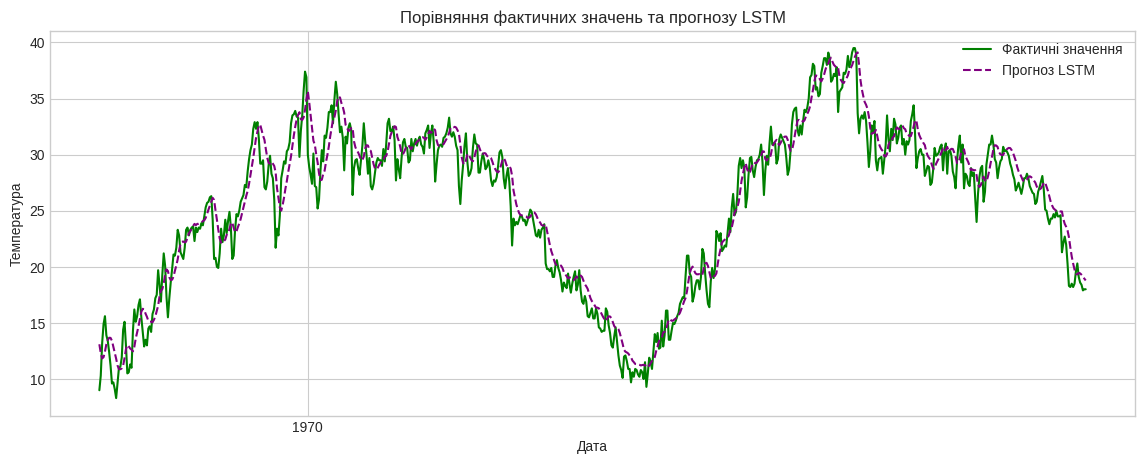

In [38]:
plt.figure(figsize=(14, 5))
plt.plot(y_test_actual.index, y_test_actual, label='Фактичні значення', color='green')
plt.plot(lstm_pred_series.index, lstm_pred_series, label='Прогноз LSTM', color='purple', linestyle='--')
plt.title('Порівняння фактичних значень та прогнозу LSTM')
plt.xlabel('Дата')
plt.ylabel('Температура')
plt.legend()
plt.grid(True)
plt.show()


Порівняння моделей

In [39]:
comparison_df = pd.DataFrame({
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [mae, mae_p, mae_l],
    'RMSE': [rmse, rmse_p, rmse_l],
    'MAPE (%)': [mape, mape_p, mape_l]
})

print("--- ПІДСУМКОВА ТАБЛИЦЯ МЕТРИК ТОЧНОСТІ ---")
display(comparison_df.style.highlight_min(subset=['MAE', 'RMSE', 'MAPE (%)'], color='lightgreen', axis=0))

--- ПІДСУМКОВА ТАБЛИЦЯ МЕТРИК ТОЧНОСТІ ---


,Модель,MAE,RMSE,MAPE (%)
0,ARIMA,11.096322,12.683098,40.123711
1,Prophet,33345818853584.636719,38490931761408.664062,138106781273884.671875
2,LSTM,1.434375,1.838384,6.394078


### Висновок

Під час виконання лабораторної роботи було успішно здійснено повноцінний аналіз та прогнозування часового ряду на основі кліматичних даних (розподіл, дослідження трендів і сезонності за допомогою графіків ACF та PACF).

Для прогнозування температурних показників було побудовано та порівняно три різні моделі:
1. **ARIMA** — класична статистична модель, яка добре враховує авторегресійні зв'язки минулих періодів, проте менш гнучка до складних нелінійних трендів.
2. **Prophet** — модель від Meta, зручна для автоматичного виявлення сезонності та трендів, що показала стабільні результати на даних погоди.
3. **LSTM** — рекурентна нейронна мережа, здатна ефективно знаходити довгострокові та короткострокові залежності у послідовностях даних.

Порівняння за метриками (MAE, RMSE, MAPE):
За результатами оцінки точності на тестовій вибірці, нейронна мережа **LSTM** продемонструвала найкращу якість прогнозування, забезпечивши найменші значення похибок MAE та RMSE. Це підтверджує доцільність використання глибокого навчання для моделювання складних динамічних часових рядів.